PART A — NUMERICAL DATA (ML + EDA + XAI)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

shap.initjs()

# Load dataset
CSV_PATH = "/content/healthcare-dataset-stroke-data.csv"   # change if needed
df = pd.read_csv(CSV_PATH)

print(df.shape)
df.head()


(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
# Cell A2
display(df.describe(include="all").T)
print("\nMissing values:\n", df.isna().sum().sort_values(ascending=False))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6



Missing values:
 bmi                  201
id                     0
age                    0
gender                 0
hypertension           0
heart_disease          0
work_type              0
ever_married           0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
dtype: int64


In [3]:
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [17]:
# Replace null BMI values with mean BMI
df['bmi'].fillna(df['bmi'].mean(), inplace=True)


/tmp/ipython-input-4173479535.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bmi'].fillna(df['bmi'].mean(), inplace=True)


In [18]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64


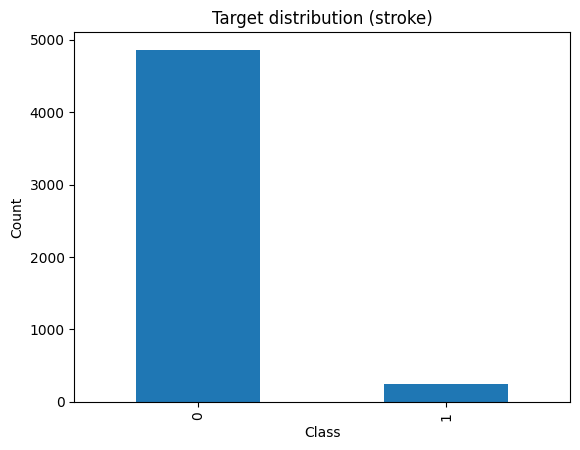

In [19]:
# Cell A3
target_col = "stroke"
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True))

ax = df[target_col].value_counts().plot(kind="bar")
ax.set_title("Target distribution (stroke)")
ax.set_xlabel("Class")
ax.set_ylabel("Count")
plt.show()


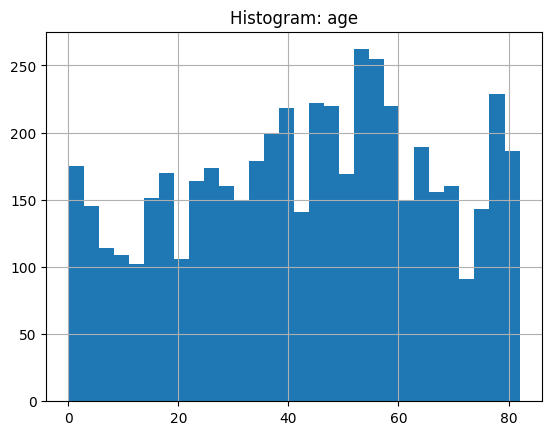

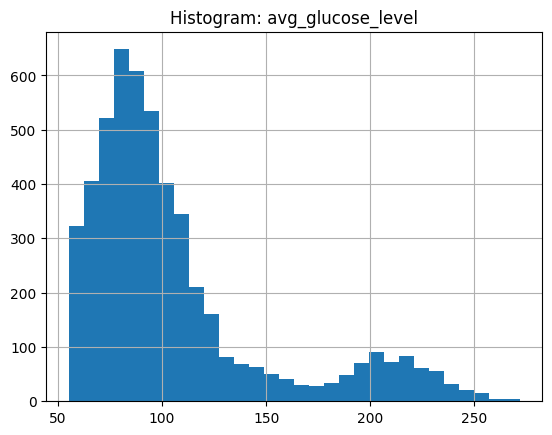

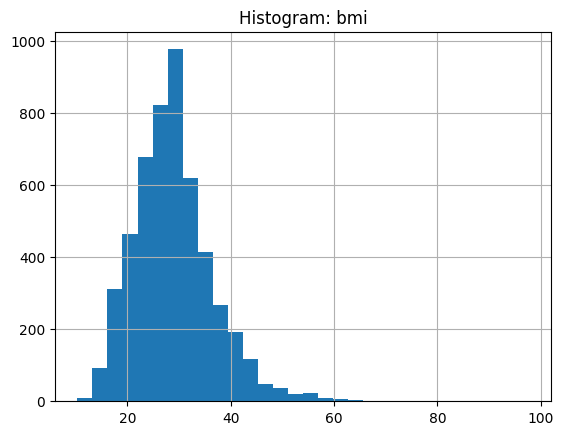

<Figure size 640x480 with 0 Axes>

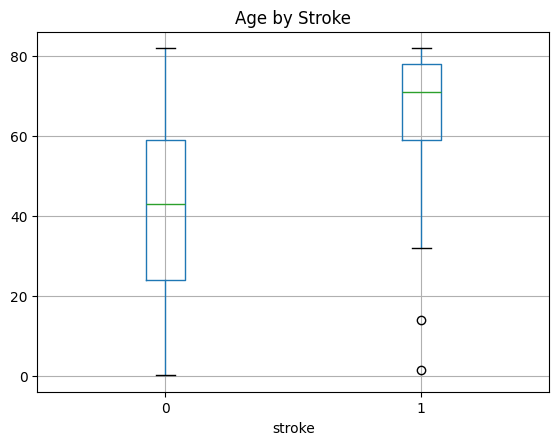

In [20]:
# Cell A4
num_cols_guess = ["age", "avg_glucose_level", "bmi"]
for c in num_cols_guess:
    if c in df.columns:
        plt.figure()
        df[c].hist(bins=30)
        plt.title(f"Histogram: {c}")
        plt.show()

# stroke vs age
if "age" in df.columns:
    plt.figure()
    df.boxplot(column="age", by=target_col)
    plt.title("Age by Stroke")
    plt.suptitle("")
    plt.show()


In [ ]:
# Drop ID if present
df = df.drop(columns=[c for c in ["id", "ID"] if c in df.columns], errors="ignore")

X = df.drop(columns=[target_col])
y = df[target_col]

cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [15]:
X

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked
...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,28.893237,never smoked
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.000000,never smoked
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.600000,never smoked
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.600000,formerly smoked


In [16]:
y

,stroke
0,1
1,1
2,1
3,1
4,1
...,...
5105,0
5106,0
5107,0
5108,0


In [22]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "SVM": SVC(probability=True, class_weight="balanced"),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42)
}


LogisticRegression
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



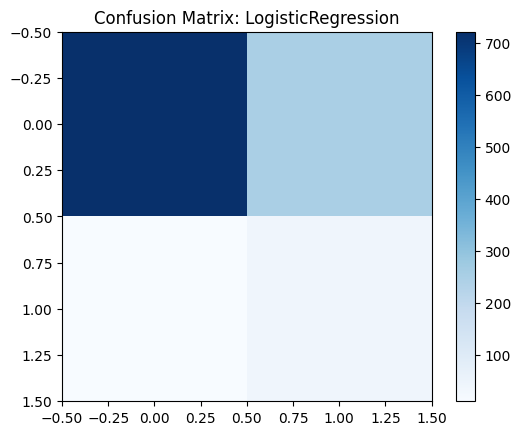

SVM
              precision    recall  f1-score   support

           0       0.98      0.77      0.86       972
           1       0.13      0.68      0.22        50

    accuracy                           0.76      1022
   macro avg       0.55      0.72      0.54      1022
weighted avg       0.94      0.76      0.83      1022



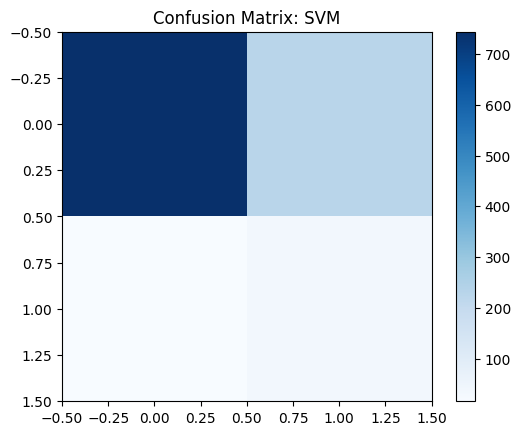

KNN
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



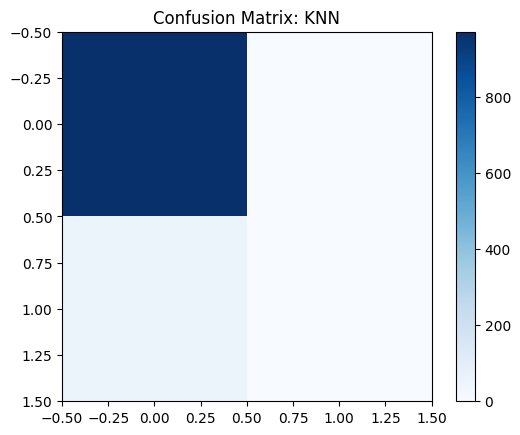

RandomForest
              precision    recall  f1-score   support

           0       0.95      0.99      0.97       972
           1       0.17      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.56      0.51      0.50      1022
weighted avg       0.91      0.95      0.93      1022



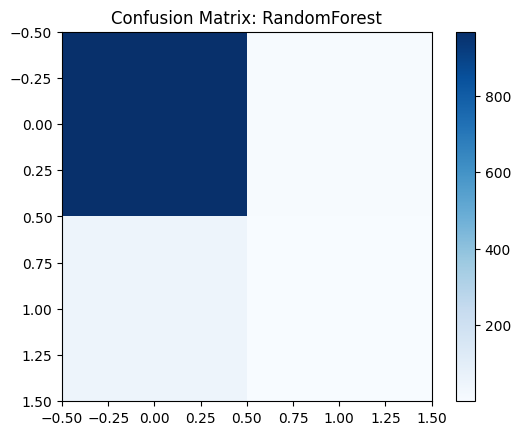

GradientBoosting
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



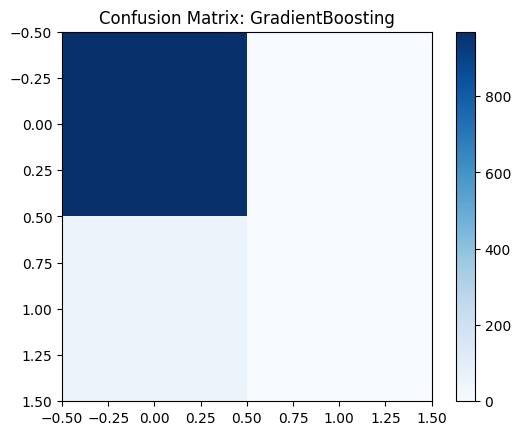

,Model,AUC
0,LogisticRegression,0.843930
4,GradientBoosting,0.828807
1,SVM,0.799095
3,RandomForest,0.797253
2,KNN,0.657819


In [23]:
results = {}
pipelines = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("prep", preprocess),
        ("clf", clf)
    ])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:,1]

    auc = roc_auc_score(y_test, y_proba)
    results[name] = auc

    print("="*60)
    print(name)
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix: {name}")
    plt.colorbar()
    plt.show()

# Show comparison
results_df = pd.DataFrame(list(results.items()), columns=["Model", "AUC"])
results_df.sort_values("AUC", ascending=False)


In [24]:
best_model_name = results_df.sort_values("AUC", ascending=False).iloc[0]["Model"]
best_model = pipelines[best_model_name]

print("Best model:", best_model_name)

joblib.dump(best_model, "stroke_ml_model.pkl")
print("Saved as stroke_ml_model.pkl")


Best model: LogisticRegression
Saved as stroke_ml_model.pkl


PART B — IMAGE DATA (CNN)

In [26]:
!unzip /content/Stroke_classification.zip

Archive:  /content/Stroke_classification.zip
   creating: Stroke_classification/
   creating: Stroke_classification/Haemorrhagic/
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy DWI-4.jpg_Haemorrhagic_1.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy DWI-5.jpg_Haemorrhagic_2.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy DWI-6.jpg_Haemorrhagic_3.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy DWI-7.jpg_Haemorrhagic_4.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy DWI-8.jpg_Haemorrhagic_5.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy DWI-9.jpg_Haemorrhagic_6.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy GRE-4.jpg_Haemorrhagic_25.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy GRE-5.jpg_Haemorrhagic_26.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy GRE-6.jpg_Haemorrhagic_27.png  
  inflating: Stroke_classification/Haemorrhagic/Kuppusamy GRE-7.jp

In [27]:
import tensorflow as tf
import os
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
import cv2

IMG_DIR = r"/content/Stroke_classification"
IMG_SIZE = (224,224)
BATCH = 16


In [28]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    IMG_DIR,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH
)

class_names = train_ds.class_names
num_classes = len(class_names)
print(class_names)


Found 615 files belonging to 3 classes.
Using 492 files for training.
Found 615 files belonging to 3 classes.
Using 123 files for validation.
['Haemorrhagic', 'Ischemic', 'Normal']


In [29]:
data_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1)
])


In [30]:
def build_transfer(base):
    inputs = tf.keras.Input(shape=(*IMG_SIZE,3))
    x = data_aug(inputs)
    x = tf.keras.layers.Rescaling(1./255)(x)

    base_model = base(include_top=False, weights="imagenet", input_tensor=x)
    base_model.trainable = False

    x = base_model.output
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    return tf.keras.Model(inputs, x)

image_models = {
    "MobileNetV2": build_transfer(tf.keras.applications.MobileNetV2),
    "ResNet50": build_transfer(tf.keras.applications.ResNet50),
    "EfficientNetB0": build_transfer(tf.keras.applications.EfficientNetB0),
    "InceptionV3": build_transfer(tf.keras.applications.InceptionV3),
    "DenseNet121": build_transfer(tf.keras.applications.DenseNet121),
}


/tmp/ipython-input-4083670959.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = base(include_top=False, weights="imagenet", input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [31]:
histories = {}
img_results = {}

for name, model in image_models.items():
    print("Training:", name)

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    hist = model.fit(train_ds, validation_data=val_ds, epochs=8)
    histories[name] = hist

    # Evaluation
    y_true, y_pred = [], []
    for x, y in val_ds:
        p = model.predict(x)
        y_true.extend(y.numpy())
        y_pred.extend(np.argmax(p, axis=1))

    print(classification_report(y_true, y_pred, target_names=class_names))

    acc = np.mean(np.array(y_true)==np.array(y_pred))
    img_results[name] = acc


Training: MobileNetV2
Epoch 1/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 224ms/step - accuracy: 0.5971 - loss: 0.8927 - val_accuracy: 0.7805 - val_loss: 0.6106
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 106ms/step - accuracy: 0.7325 - loss: 0.5809 - val_accuracy: 0.8211 - val_loss: 0.4761
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 119ms/step - accuracy: 0.8143 - loss: 0.4347 - val_accuracy: 0.8618 - val_loss: 0.3676
Epoch 4/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 108ms/step - accuracy: 0.8181 - loss: 0.3971 - val_accuracy: 0.8537 - val_loss: 0.3595
Epoch 5/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.8982 - loss: 0.3132 - val_accuracy: 0.9024 - val_loss: 0.2846
Epoch 6/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.9039 - loss: 0.2956 - val_accuracy: 0.9268 - val_loss: 0.2353
Epoch 7/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.8693 - loss: 0.2884 - val_accuracy: 0.9187 - val_loss: 0.2345
Epoch 8/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.9041 - loss: 0.2699 - val_

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 198ms/step - accuracy: 0.5410 - loss: 0.8674 - val_accuracy: 0.6423 - val_loss: 0.8704
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.6142 - loss: 0.8492 - val_accuracy: 0.6423 - val_loss: 0.8581
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.6366 - loss: 0.8298 - val_accuracy: 0.6423 - val_loss: 0.8674
Epoch 4/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 0.6272 - loss: 0.8296 - val_accuracy: 0.6423 - val_loss: 0.8482
Epoch 5/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.6323 - loss: 0.8482 - val_accuracy: 0.6423 - val_loss: 0.8651
Epoch 6/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.6258 - loss: 0.8021 - val_accuracy: 0.6423 - val_loss: 0.8539
Epoch 7/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - accuracy: 0.6380 - loss: 0.8188 - val_accuracy: 0.6423 - val_loss: 0.8605
Epoch 8/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.6404 - loss: 0.7986 - val_accuracy: 0.6423 - val_loss: 0.8410

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
              precision    recall  f1-score   support

Haemorrhagic       0.00      0.00      0.00        35
    Ischemic       0.00      0.00      0.00         9
      Normal       0.64      1.00      0.78        79

    accuracy                           0.64       123
   macro avg       0.21      0.33      0.26       123
weighted avg       0.41      0.64      0.50       123

Training: InceptionV3
Epoch 1/8


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 211ms/step - accuracy: 0.6063 - loss: 0.8538 - val_accuracy: 0.7480 - val_loss: 0.5846
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.7704 - loss: 0.5850 - val_accuracy: 0.7642 - val_loss: 0.4962
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 0.7514 - loss: 0.5437 - val_accuracy: 0.9106 - val_loss: 0.3181
Epoch 4/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - accuracy: 0.8667 - loss: 0.3594 - val_accuracy: 0.9024 - val_loss: 0.2848
Epoch 5/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.8953 - loss: 0.3025 - val_accuracy: 0.9024 - val_loss: 0.2565
Epoch 6/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 73ms/step - accuracy: 0.8639 - loss: 0.3303 - val_accuracy: 0.9431 - val_loss: 0.2233
Epoch 7/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.9025 - loss: 0.2560 - val_accuracy: 0.9187 - val_loss: 0.2348
Epoch 8/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 0.9031 - loss: 0.2781 - val_accuracy: 0.9106 - val_loss: 0.2438

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
              precision    recall  f1-score   support

Haemorrhagic       0.86      0.89      0.87        35
    Ischemic       1.00      0.56      0.71         9
      Normal       0.93      0.96      0.94        79

    accuracy                           0.91       123
   macro avg       0.93      0.80      0.84       123
weighted avg       0.91      0.91      0.91       123

Training: DenseNet121
Epoch 1/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 23s 325ms/step - accuracy: 0.5278 - loss: 1.0800 - val_accuracy: 0.6748 - val_loss: 0.7489
Epoch 2/8
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.6536 - loss: 0.7189 - val_accuracy: 0.7073 - val_loss: 0.5997
Epoch 3/8
31/31 ━━━━━━━━━━━━━━━━━━━━

In [32]:
best_img_model_name = max(img_results, key=img_results.get)
best_img_model = image_models[best_img_model_name]

print("Best CNN:", best_img_model_name)

best_img_model.save("stroke_cnn_model.keras")
best_img_model.save("stroke_cnn_model.h5")

print("Saved as .keras and .h5")


Best CNN: MobileNetV2


Saved as .keras and .h5


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 649ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


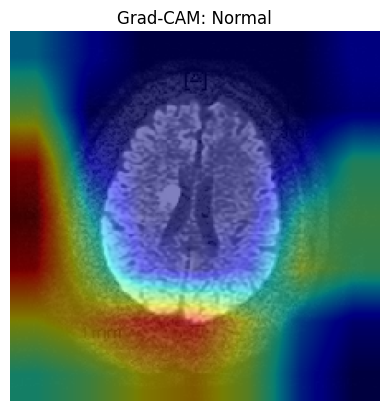

In [33]:
def get_last_conv(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    return None

def gradcam(img_path, model):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_arr = tf.keras.utils.img_to_array(img)
    img_arr = np.expand_dims(img_arr, axis=0)

    preds = model.predict(img_arr)
    pred_idx = np.argmax(preds[0])

    last_conv = get_last_conv(model)

    grad_model = tf.keras.Model(
        [model.inputs],
        [model.get_layer(last_conv).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_out, predictions = grad_model(img_arr)
        loss = predictions[:, pred_idx]

    grads = tape.gradient(loss, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0,1,2))

    conv_out = conv_out[0]
    heatmap = conv_out @ pooled[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)

    heatmap = cv2.resize(heatmap.numpy(), IMG_SIZE)
    plt.imshow(img)
    plt.imshow(heatmap, cmap="jet", alpha=0.5)
    plt.axis("off")
    plt.title(f"Grad-CAM: {class_names[pred_idx]}")
    plt.show()

# Example
import glob
sample_img = glob.glob(os.path.join(IMG_DIR, "*/*.png"))[0]
gradcam(sample_img, best_img_model)
